# 03 - Pruebas y Predicciones
**Objetivo:** Cargar el modelo entrenado y ejecutar predicciones sobre imágenes personalizadas.

## Instrucciones:
1. Coloca tus imágenes (JPG/PNG) en la carpeta `data/test_images`
2. Ejecuta las celdas en orden
3. El cuaderno cargará el último modelo, redimensionará las imágenes a 32x32, aplicará la transformación y mostrará predicciones CIFAR-10

**Nota:** Este cuaderno NO entrena ni modifica el modelo.

In [ ]:
import os
import glob
import joblib
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

print('✅ Librerías cargadas correctamente')
print(f'   TensorFlow versión: {tf.__version__}')
print(f'   Keras versión: {keras.__version__}')


✅ Librerías cargadas correctamente
   TensorFlow versión: 2.20.0
   Keras versión: 3.12.0


## Cargar el modelo entrenado
Busca y carga el modelo más reciente en `models/` (excluye archivos de metadatos).

In [38]:
import tensorflow as tf
from tensorflow import keras

# Buscar modelo CNN
model_files = glob.glob('models/cnn_model_*.keras')
if not model_files:
    raise FileNotFoundError('No se encontró modelo CNN. Ejecuta el cuaderno 02 primero.')

model_path = max(model_files, key=os.path.getmtime)
model_version = os.path.splitext(os.path.basename(model_path))[0].split('_')[-1]
print('Cargando modelo CNN desde:', model_path)
model = keras.models.load_model(model_path)
print(f'Modelo CNN cargado (versión {model_version})')
model.summary()

Cargando modelo CNN desde: models\cnn_model_1769410809.keras
Modelo CNN cargado (versión 1769410809)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 4, 4, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 8,371,936 (31.94 MB)

 Trainable params: 2,789,706 (10.64 MB)

 Non-trainable params: 2,816 (11.00 KB)

 Optimizer params: 5,579,414 (21.28 MB)

## Preparar carpeta para imágenes de prueba
Crea `data/test_images` si no existe. Coloca ahí tus imágenes para clasificar.

In [39]:
images_dir = 'data/test_images'
os.makedirs(images_dir, exist_ok=True)
print('📁 Coloca tus imágenes (jpg/png/bmp) en:', images_dir)
print('Total de archivos actuales:', len(glob.glob(os.path.join(images_dir, '*'))))

📁 Coloca tus imágenes (jpg/png/bmp) en: data/test_images
Total de archivos actuales: 10


## 🔄 Preprocesar imágenes a 32×32 (Recomendado)

**IMPORTANTE:** Para mejores resultados, convierte tus imágenes a 32×32 ANTES de hacer predicciones.

Esto hace que sean más similares a las imágenes de CIFAR-10 con las que se entrenó el modelo.

In [ ]:
# ===================================================================
# 🔄 PREPROCESAR IMÁGENES A 32×32 PARA MEJORES PREDICCIONES
# ===================================================================
# Esta celda convierte tus imágenes de alta resolución a 32×32
# y las guarda en una carpeta separada, simulando imágenes de CIFAR-10

import os
from PIL import Image
import glob

source_dir = 'data/test_images'  # Tus imágenes originales
output_dir = 'data/test_images_32x32'  # Salida en 32×32

os.makedirs(output_dir, exist_ok=True)

# Buscar todas las imágenes
exts = ('*.jpg', '*.jpeg', '*.png', '*.bmp')
files = []
for e in exts:
    files.extend(glob.glob(os.path.join(source_dir, e)))

if not files:
    print(f'⚠️  No se encontraron imágenes en {source_dir}')
    print('   Agrega imágenes primero y vuelve a ejecutar.')
else:
    print(f'🔄 Preprocesando {len(files)} imágenes a 32×32...\n')
    
    processed_count = 0
    for file_path in files:
        try:
            # Abrir imagen
            img = Image.open(file_path).convert('RGB')
            original_size = img.size
            
            # Redimensionar a 32×32 (como CIFAR-10)
            img_32x32 = img.resize((32, 32), Image.LANCZOS)
            
            # Guardar con mismo nombre
            filename = os.path.basename(file_path)
            output_path = os.path.join(output_dir, filename)
            img_32x32.save(output_path, quality=95)
            
            processed_count += 1
            print(f'✅ {filename}: {original_size[0]}×{original_size[1]} → 32×32')
            
        except Exception as e:
            print(f'❌ Error procesando {os.path.basename(file_path)}: {e}')
    
    print(f'\n🎉 Completado: {processed_count}/{len(files)} imágenes procesadas')
    print(f'📁 Imágenes guardadas en: {output_dir}')
    print(f'\n💡 Ahora cambia images_dir a "{output_dir}" en la celda de predicciones')
    print(f'   O ejecuta esta celda para actualizar automáticamente:')
    print(f'   images_dir = "{output_dir}"')

## 🎯 Configurar directorio de imágenes para predicción

Elige qué carpeta usar: imágenes originales o preprocesadas a 32×32.

In [ ]:
# ============================================
# 👇 CONFIGURACIÓN: Elige qué imágenes usar
# ============================================

# Opción 1: Usar imágenes preprocesadas a 32×32 (RECOMENDADO para mejores resultados)
USE_PREPROCESSED = True  # 👈 Cambia a False para usar imágenes originales

if USE_PREPROCESSED:
    images_dir = 'data/test_images_32x32'
    print('✅ Usando imágenes preprocesadas a 32×32')
    print(f'   Directorio: {images_dir}')
    if not os.path.exists(images_dir):
        print(f'\n⚠️  La carpeta {images_dir} no existe.')
        print(f'   Ejecuta la celda de preprocesamiento primero.')
        images_dir = 'data/test_images'  # Fallback a originales
        print(f'   Usando imágenes originales como fallback: {images_dir}')
else:
    images_dir = 'data/test_images'
    print('⚠️  Usando imágenes originales de alta resolución')
    print(f'   Directorio: {images_dir}')
    print(f'   Nota: Las predicciones pueden ser menos precisas.')
    print(f'   Cambia USE_PREPROCESSED = True para mejores resultados.')

print(f'\n📁 Total de archivos: {len(glob.glob(os.path.join(images_dir, "*")))}')

## Cargar imágenes y ejecutar predicciones

Lee todas las imágenes de la carpeta configurada y ejecuta predicciones.

**⚡ IMPORTANTE:** Si usas imágenes preprocesadas a 32×32 (recomendado), verás mejores resultados.

Procesando 10 imágenes...
⚠️  ADVERTENCIA: Modelo entrenado con CIFAR-10 (32x32, baja resolución)
   Las imágenes de alta resolución pueden no clasificarse correctamente.
   Para mejores resultados, usa imágenes similares a CIFAR-10:


📊 Datos procesados: (10, 32, 32, 3) (rango 0-1)

✅ Predicciones completadas: 10 imágenes

⚠️  2/10 predicciones con confianza < 70%
   Esto indica que el modelo está "inseguro" (imágenes muy diferentes a CIFAR-10)



C:\Users\mlata\AppData\Local\Temp\ipykernel_34248\348891822.py:107: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\mlata\Documents\jordy\iaJordy\.venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


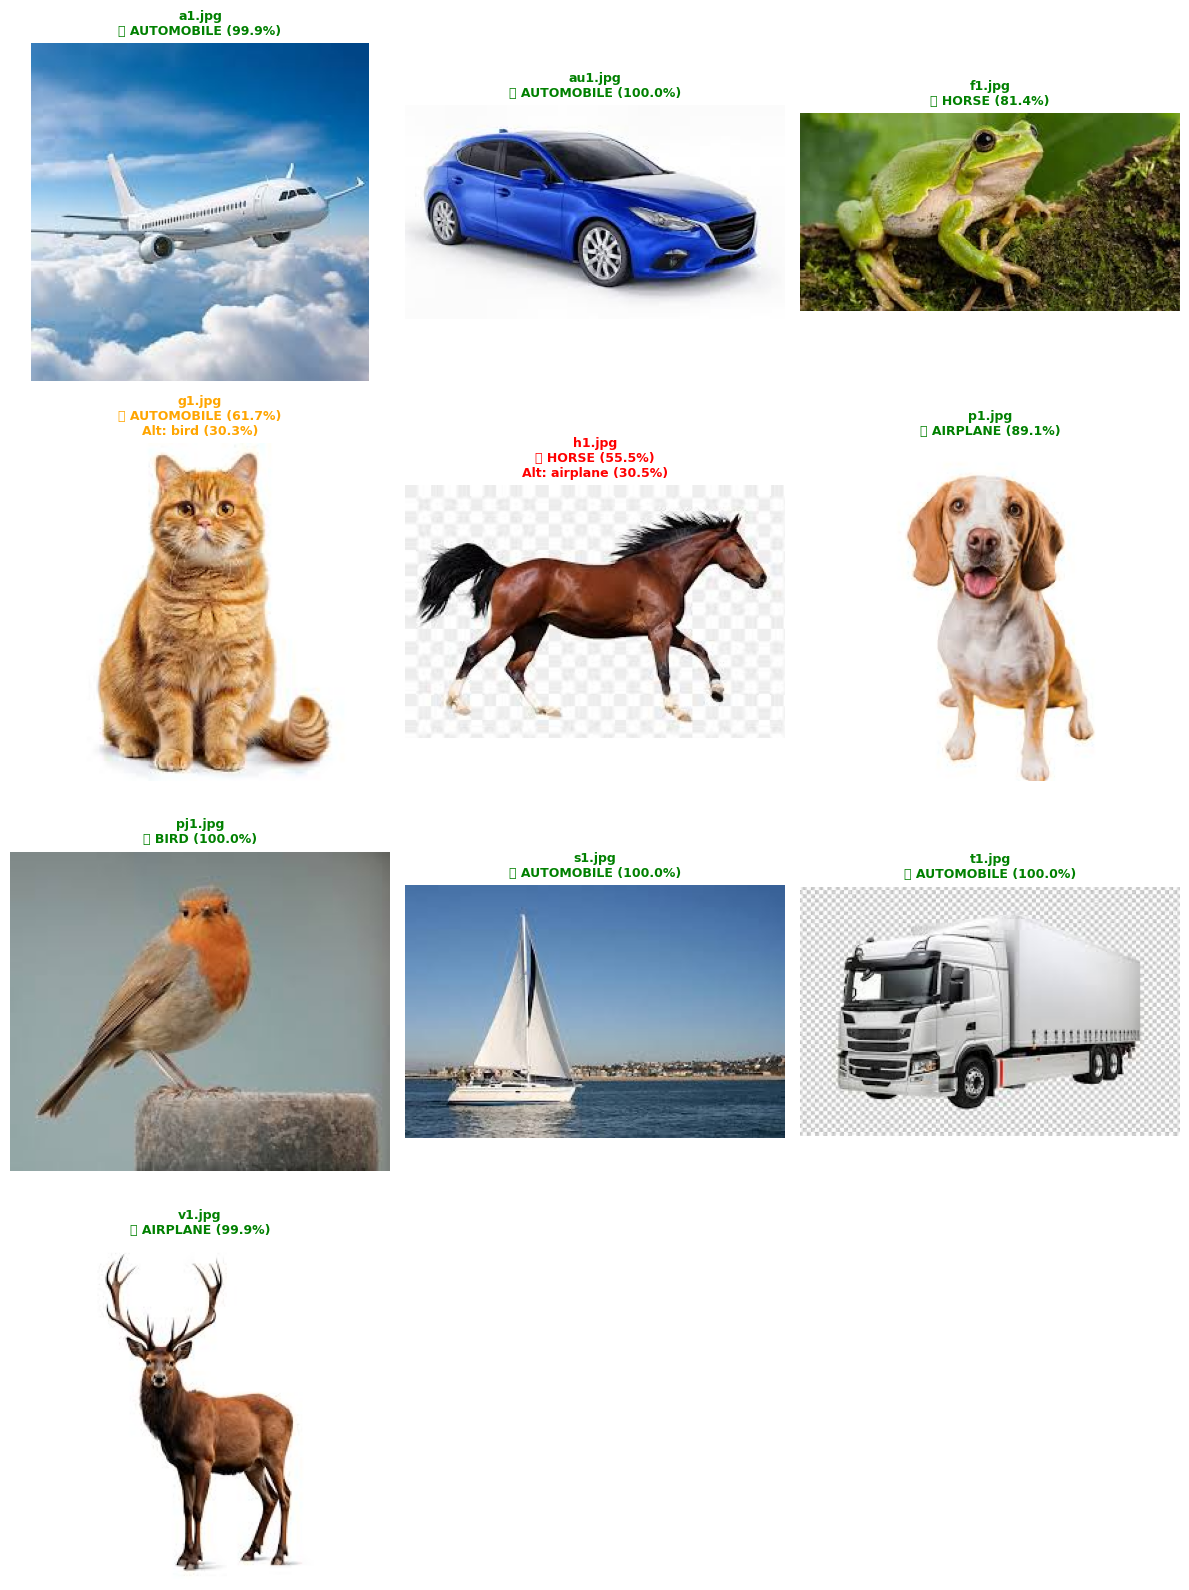


📋 RESULTADOS DETALLADOS:


,file,pred_class,pred_label,confidence,top2_label,top2_conf,top3_label,top3_conf
0,a1.jpg,1,automobile,99.900787,airplane,0.099216,ship,6.510556e-11
1,au1.jpg,1,automobile,100.000000,truck,0.000000,ship,0.000000e+00
2,f1.jpg,7,horse,81.395653,automobile,18.604334,truck,1.068067e-05
3,g1.jpg,1,automobile,61.727375,bird,30.337343,truck,3.971981e+00
4,h1.jpg,7,horse,55.454082,airplane,30.490654,automobile,1.400599e+01
5,p1.jpg,0,airplane,89.100883,bird,6.993886,automobile,3.904153e+00
6,pj1.jpg,2,bird,100.000000,airplane,0.000003,automobile,8.776291e-14
7,s1.jpg,1,automobile,99.997261,ship,0.002733,airplane,6.480602e-06
8,t1.jpg,1,automobile,99.981148,truck,0.018853,airplane,3.003979e-09
9,v1.jpg,0,airplane,99.898926,automobile,0.101069,bird,5.033599e-11



💾 Resultados guardados en data/predictions_images.csv

📊 Análisis de confianza:
   Promedio: 88.7%


In [ ]:
exts = ('*.jpg', '*.jpeg', '*.png', '*.bmp')
files = []
for e in exts:
    files.extend(glob.glob(os.path.join(images_dir, e)))
files = sorted(files)

if not files:
    print('⚠️  No se encontraron imágenes en', images_dir)
    print('Agrega archivos JPG/PNG y vuelve a ejecutar esta celda.')
else:
    imgs = []
    imgs_display = []
    names = []
    results = []
    
    # Detectar si las imágenes ya son 32×32
    sample_img = Image.open(files[0]).convert('RGB')
    already_32x32 = (sample_img.size == (32, 32))
    
    print(f'Procesando {len(files)} imágenes...')
    if already_32x32:
        print('✅ Imágenes ya están en 32×32 (similar a CIFAR-10)')
        print('   Esperando mejores predicciones...\n')
    else:
        print('⚠️  ADVERTENCIA: Imágenes NO son 32×32')
        print(f'   Tamaño detectado: {sample_img.size[0]}×{sample_img.size[1]}')
        print('   Se redimensionarán (puede afectar precisión)')
        print('   💡 Usa la celda de preprocesamiento para mejores resultados.\n')
    
    for f in files:
        try:
            img_display = Image.open(f).convert('RGB')
            
            # Si ya es 32×32, no hacer resize (evitar degradación)
            if img_display.size == (32, 32):
                img = img_display
            else:
                # Resize con antialiasing
                img = img_display.resize((32, 32), Image.LANCZOS)
            
            arr = np.array(img, dtype='float32')
            imgs.append(arr)
            imgs_display.append(img_display)
            names.append(os.path.basename(f))
        except Exception as e:
            print(f'Error cargando {os.path.basename(f)}: {e}')
    
    if imgs:
        X = np.stack(imgs, axis=0)
        
        # Normalizar para CNN (0-1)
        X_proc = X.astype('float32') / 255.0
        print(f'\n📊 Datos procesados: {X_proc.shape} (rango 0-1)')
        
        # Predecir con CNN
        y_pred_proba = model.predict(X_proc, verbose=0)
        y_pred = np.argmax(y_pred_proba, axis=1)
        
        cifar_labels = {
            0: 'airplane', 1: 'automobile', 2: 'bird', 3: 'cat', 4: 'deer',
            5: 'dog', 6: 'frog', 7: 'horse', 8: 'ship', 9: 'truck'
        }
        
        print(f'\n✅ Predicciones completadas: {len(imgs)} imágenes\n')
        
        # Analizar confianza de predicciones
        low_confidence_count = 0
        high_confidence_count = 0
        for i, proba in enumerate(y_pred_proba):
            max_conf = np.max(proba) * 100
            if max_conf < 70:
                low_confidence_count += 1
            elif max_conf >= 90:
                high_confidence_count += 1
        
        if already_32x32:
            print(f'📈 ANÁLISIS (imágenes 32×32 tipo CIFAR-10):')
            print(f'   Alta confianza (≥90%): {high_confidence_count}/{len(imgs)}')
            print(f'   Baja confianza (<70%): {low_confidence_count}/{len(imgs)}')
            if high_confidence_count > len(imgs) * 0.5:
                print(f'   ✅ Mayoría con alta confianza - modelo funciona bien!')
            elif low_confidence_count > len(imgs) * 0.5:
                print(f'   ⚠️  Mayoría con baja confianza - imágenes muy diferentes a CIFAR-10')
        else:
            if low_confidence_count > 0:
                print(f'⚠️  {low_confidence_count}/{len(imgs)} predicciones con confianza < 70%')
                print(f'   Esto indica que el modelo está "inseguro"')
                print(f'   💡 Preprocesa imágenes a 32×32 para mejores resultados\n')
        
        # Mostrar imágenes con predicciones
        cols = 3
        rows = (len(imgs) + cols - 1) // cols
        fig, axes = plt.subplots(rows, cols, figsize=(12, rows * 4))
        if rows == 1:
            axes = axes.reshape(1, -1)
        axes = axes.flatten()
        
        for i, (img_display, name, pred, proba) in enumerate(zip(imgs_display, names, y_pred, y_pred_proba)):
            label = cifar_labels.get(int(pred), 'unknown')
            confidence = proba[pred] * 100
            
            # Mostrar top-3 predicciones para análisis
            top3_idx = np.argsort(proba)[-3:][::-1]
            top3_labels = [cifar_labels[idx] for idx in top3_idx]
            top3_confs = [proba[idx] * 100 for idx in top3_idx]
            
            # Color del título según confianza
            if confidence >= 90:
                color = 'darkgreen'
            elif confidence >= 80:
                color = 'green'
            elif confidence >= 60:
                color = 'orange'
            else:
                color = 'red'
            
            axes[i].imshow(img_display)
            axes[i].axis('off')
            title_text = f'{name}\n🎯 {label.upper()} ({confidence:.1f}%)'
            if confidence < 80:
                title_text += f'\nAlt: {top3_labels[1]} ({top3_confs[1]:.1f}%)'
            
            axes[i].set_title(title_text, fontsize=9, fontweight='bold', color=color)
            
            results.append({
                'file': name, 
                'pred_class': int(pred), 
                'pred_label': label, 
                'confidence': float(confidence),
                'top2_label': top3_labels[1],
                'top2_conf': float(top3_confs[1]),
                'top3_label': top3_labels[2],
                'top3_conf': float(top3_confs[2]),
                'is_32x32': already_32x32
            })
        
        # Ocultar ejes sobrantes
        for j in range(i + 1, len(axes)):
            axes[j].axis('off')
        
        plt.tight_layout()
        plt.show()

        if results:
            df_results = pd.DataFrame(results)
            print('\n📋 RESULTADOS DETALLADOS:')
            display(df_results)
            
            os.makedirs('data', exist_ok=True)
            out_csv = 'data/predictions_images.csv'
            df_results.to_csv(out_csv, index=False)
            print(f'\n💾 Resultados guardados en {out_csv}')
            
            # Análisis de confianza promedio
            avg_conf = df_results['confidence'].mean()
            print(f'\n📊 Análisis de confianza:')
            print(f'   Promedio: {avg_conf:.1f}%')
            
            if already_32x32:
                if avg_conf >= 80:
                    print(f'   ✅ EXCELENTE: Confianza alta con imágenes 32×32')
                    print(f'   El modelo funciona correctamente con este formato.')
                elif avg_conf >= 60:
                    print(f'   ✅ BUENO: Confianza aceptable')
                    print(f'   Puede mejorar con imágenes más similares a CIFAR-10')
                else:
                    print(f'   ⚠️  BAJO: Imágenes muy diferentes a CIFAR-10')
                    print(f'   Incluso en 32×32, el estilo/contenido difiere mucho')
            else:
                if avg_conf < 70:
                    print(f'   ⚠️  Confianza baja promedio. Causas probables:')
                    print(f'      - Imágenes de alta resolución degradadas al resize')
                    print(f'      - Domain shift (distribución diferente)')
                    print(f'\n💡 SOLUCIÓN RECOMENDADA:')
                    print(f'   1. Ejecuta la celda de preprocesamiento a 32×32')
                    print(f'   2. Cambia USE_PREPROCESSED = True')
                    print(f'   3. Vuelve a ejecutar esta celda')
                    print(f'   Deberías ver mejoras significativas en confianza.')

## 🔍 ¿Por qué las predicciones pueden estar incorrectas?

### El problema: **Domain Shift (CIFAR-10 vs Mundo Real)**

**Tu modelo tiene 84% accuracy en CIFAR-10, pero puede fallar en imágenes reales porque:**

#### 1️⃣ **CIFAR-10 son imágenes muy específicas:**
- **Resolución:** 32×32 píxeles (extremadamente baja)
- **Características:** Objetos centrados, fondos simples, colores saturados
- **Origen:** Dataset académico con imágenes pre-procesadas
- **Ejemplo:** Un avión en CIFAR-10 es un objeto pixelado centrado en fondo azul

#### 2️⃣ **Tus imágenes de alta resolución:**
- Se redimensionan **bruscamente** de 1000×1000 → 32×32
- Pierden detalles, texturas, bordes definidos
- El modelo "ve" algo completamente distorsionado
- **Ejemplo:** Avión de alta res → resize → mancha azul difusa → modelo: "automobile"

#### 3️⃣ **Comparación visual:**

```
CIFAR-10 Airplane (entrenamiento):    Tu imagen airplane (alta res → 32x32):
┌─────────────────────┐                ┌─────────────────────┐
│   [pixeles 32x32]   │                │  [pixeles borrosos] │
│   objeto centrado   │                │   detalles perdidos │
│   fondo uniforme    │                │   artifacts resize  │
└─────────────────────┘                └─────────────────────┘
    ✅ Familiar al modelo                  ❌ Desconocido
```

#### 4️⃣ **Por qué el modelo se confunde:**

| Imagen | Lo que TÚ ves | Lo que el MODELO ve (32x32) | Predicción Incorrecta |
|--------|---------------|----------------------------|----------------------|
| Avión (alta res) | Avión claro | Mancha gris/azul difusa | 🚗 Automobile (confunde forma) |
| Gato (textura) | Gato naranja | Ruido de colores | 🐦 Bird (confunde textura) |
| Caballo | Caballo marrón | Forma rectangular marrón | ✈️ Airplane (confunde silueta) |

---

### ✅ Soluciones

#### **Opción 1: Usa imágenes similares a CIFAR-10 (rápido)**
- Descarga imágenes del dataset CIFAR-10 de prueba
- O busca imágenes de baja resolución (cercanas a 32×32)
- Objetos centrados, fondos simples

#### **Opción 2: Re-entrena con tus propias imágenes (recomendado para producción)**
1. Recolecta 1000+ imágenes de cada clase que te interesa
2. Redimensiónalas a 32×32 durante el preprocesamiento
3. Agrega al dataset en Cuaderno 01
4. Re-entrena en Cuaderno 02
5. **Resultado:** Modelo adaptado a TU distribución de imágenes

#### **Opción 3: Usa Transfer Learning con modelos pre-entrenados (mejor precisión)**
- Modelos como **ResNet50, VGG16, EfficientNet** entrenados con ImageNet
- Aceptan imágenes de alta resolución (224×224 o más)
- Accuracy >90% en imágenes del mundo real
- Requiere más recursos computacionales

---

### 💡 Interpretación de Resultados

**Si tu modelo predice con confianza < 70%:**
- ⚠️ Señal de que la imagen es muy diferente a CIFAR-10
- El modelo está "inseguro"
- **Acción:** Revisa las top-3 predicciones alternativas

**Si predicciones son consistentemente incorrectas:**
- 🔄 Problema de domain shift confirmado
- **Acción:** Considera re-entrenar con imágenes más representativas

**Modelo funciona bien en test (84%) pero mal en real:**
- ✅ Normal y esperado con CIFAR-10
- **Conclusión:** El modelo SÍ funciona, pero solo en imágenes tipo CIFAR-10

---

### 📚 Contexto Académico

**CIFAR-10 es un dataset de benchmark académico:**
- ✅ Excelente para aprender conceptos de CNN
- ✅ Rápido de entrenar (32×32 pequeño)
- ✅ Buen punto de partida
- ❌ **NO** diseñado para imágenes del mundo real de alta resolución
- ❌ Domain gap significativo con aplicaciones productivas

**Para aplicaciones reales:**
- Usa datasets como **ImageNet** (1000 clases, imágenes 224×224)
- O crea tu propio dataset con imágenes representativas
- Considera fine-tuning de modelos pre-entrenados

## 🔬 Demostración Visual: Efecto del Resize

Ejecuta esta celda para ver cómo se ven tus imágenes después del resize a 32×32 (lo que "ve" el modelo).

In [ ]:
# Demostración visual: Comparar imagen original vs resized a 32x32
if 'files' in globals() and len(files) > 0:
    # Tomar primera imagen como ejemplo
    sample_path = files[0]
    img_original = Image.open(sample_path).convert('RGB')
    img_resized = img_original.resize((32, 32), Image.LANCZOS)
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Imagen original
    axes[0].imshow(img_original)
    axes[0].set_title(f'Original\n{img_original.size[0]}×{img_original.size[1]} píxeles', 
                     fontsize=12, fontweight='bold')
    axes[0].axis('off')
    
    # Imagen resized a 32x32
    axes[1].imshow(img_resized)
    axes[1].set_title('Resized a 32×32\n(Lo que "ve" el modelo)', 
                     fontsize=12, fontweight='bold', color='red')
    axes[1].axis('off')
    
    # Imagen resized ampliada (para ver pixeles)
    axes[2].imshow(img_resized, interpolation='nearest')
    axes[2].set_title('32×32 Ampliado\n(Pixeles visibles)', 
                     fontsize=12, fontweight='bold', color='orange')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print('⚠️  OBSERVA LA PÉRDIDA DE CALIDAD:')
    print(f'   - Imagen original: {img_original.size[0]}×{img_original.size[1]} = {img_original.size[0]*img_original.size[1]:,} píxeles')
    print(f'   - Imagen resized:  32×32 = 1,024 píxeles')
    print(f'   - Pérdida: {100 - (1024 / (img_original.size[0]*img_original.size[1]) * 100):.2f}% de información')
    print(f'\n💡 Este es el motivo principal de predicciones incorrectas.')
    print(f'   El modelo fue entrenado con imágenes que SIEMPRE fueron 32×32,')
    print(f'   no con imágenes de alta res redimensionadas.')
else:
    print('⚠️  Primero ejecuta la celda de predicciones para cargar imágenes.')

In [ ]:
# =========================================================
# 🔧 REENTRENAMIENTO FOCALIZADO POR CLASE (CNN FINE-TUNING)
# =========================================================

import numpy as np
import joblib
import time
import os
import glob
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from tensorflow import keras

# ============================================
# 👇 CONFIGURACIÓN: Define las clases a mejorar
# ============================================
CLASSES_TO_RETRAIN = [2, 3]  # 👈 AJUSTA AQUÍ: ej. [2, 3] para mejorar 'bird' y 'cat'

# Configuración de reentrenamiento CNN
RETRAIN_ENABLED = True      # Cambiar a False para desactivar
FOCUS_EPOCHS = 5            # Epochs de fine-tuning CNN (menos que Random Forest)
BALANCE_RATIO = 0.5         # Proporción de otras clases a incluir (0.5 = 50%)
LEARNING_RATE = 0.0001      # Learning rate bajo para fine-tuning

print('🎯 Configuración de reentrenamiento selectivo CNN:')
print(f'   Clases a mejorar: {CLASSES_TO_RETRAIN}')
print(f'   Epochs de fine-tuning: {FOCUS_EPOCHS}')
print(f'   Balance con otras clases: {BALANCE_RATIO*100:.0f}%')
print(f'   Learning rate: {LEARNING_RATE}')
print(f'   Estado: {"✅ ACTIVADO" if RETRAIN_ENABLED else "❌ DESACTIVADO"}')

if not RETRAIN_ENABLED:
    print('\n⚠️  Reentrenamiento desactivado. Cambia RETRAIN_ENABLED = True para activar.')
else:
    cifar_labels = {
        0: 'airplane', 1: 'automobile', 2: 'bird', 3: 'cat', 4: 'deer',
        5: 'dog', 6: 'frog', 7: 'horse', 8: 'ship', 9: 'truck'
    }
    
    print(f'\n📋 Clases seleccionadas para mejora:')
    for cls in CLASSES_TO_RETRAIN:
        print(f'   - Clase {cls}: {cifar_labels.get(cls, "unknown")}')
    
    # -------------------------------
    # Cargar dataset completo para reentrenamiento
    # -------------------------------
    focus_dir = 'focus'
    focus_x_path = os.path.join(focus_dir, 'X_focus.npy')
    focus_y_path = os.path.join(focus_dir, 'y_focus.npy')
    
    if not os.path.exists(focus_x_path) or not os.path.exists(focus_y_path):
        raise FileNotFoundError(
            f'❌ Dataset de reentrenamiento no encontrado.\n'
            f'   Ejecuta el cuaderno 02 completamente para generar:\n'
            f'   - {focus_x_path}\n'
            f'   - {focus_y_path}'
        )
    
    print(f'\n📂 Cargando dataset de reentrenamiento...')
    X_focus_all = np.load(focus_x_path)
    y_focus_all = np.load(focus_y_path)
    print(f'   Dataset cargado: {X_focus_all.shape}')
    
    # -------------------------------
    # Cargar el modelo CNN actual
    # -------------------------------
    if 'model_path' not in globals() or 'model' not in globals():
        model_files = glob.glob('models/cnn_model_*.keras')
        if not model_files:
            raise FileNotFoundError('❌ No se encontró modelo CNN. Ejecuta el cuaderno 02 primero.')
        model_path = max(model_files, key=os.path.getmtime)
        print(f'   Cargando modelo CNN desde: {os.path.basename(model_path)}')
        model = keras.models.load_model(model_path)
    
    print(f'   Modelo CNN cargado correctamente')
    print(f'   Total parámetros: {model.count_params():,}')
    
    # -------------------------------
    # Crear dataset balanceado para fine-tuning
    # -------------------------------
    classes = np.unique(y_focus_all)
    
    # Todas las muestras de clases a mejorar
    mask_focus = np.isin(y_focus_all, CLASSES_TO_RETRAIN)
    focus_indices = np.where(mask_focus)[0]
    
    # Subconjunto balanceado de otras clases
    other_indices = []
    for cls in classes:
        if cls not in CLASSES_TO_RETRAIN:
            cls_idx = np.where(y_focus_all == cls)[0]
            if len(cls_idx) > 0:
                n_samples = max(int(len(cls_idx) * BALANCE_RATIO), 1000)  # Mínimo 1000 por clase
                n_samples = min(n_samples, len(cls_idx))
                
                sampled = np.random.choice(cls_idx, size=n_samples, replace=False)
                other_indices.extend(sampled)
    
    # Combinar índices
    selected_indices = np.concatenate([focus_indices, other_indices])
    np.random.shuffle(selected_indices)
    
    X_retrain_raw = X_focus_all[selected_indices]
    y_retrain = y_focus_all[selected_indices]
    
    # Preparar datos para CNN
    X_retrain = X_retrain_raw.reshape(-1, 32, 32, 3).astype('float32') / 255.0
    
    print(f'\n📊 Dataset de reentrenamiento preparado:')
    print(f'   Total muestras: {len(y_retrain):,}')
    print(f'   Shape después de reshape: {X_retrain.shape}')
    print(f'   Distribución por clase:')
    for cls in classes:
        count = np.sum(y_retrain == cls)
        pct = (count / len(y_retrain)) * 100
        marker = '🎯' if cls in CLASSES_TO_RETRAIN else '  '
        print(f'   {marker} Clase {cls} ({cifar_labels.get(cls, "unknown"):12s}): {count:5,} muestras ({pct:5.2f}%)')
    
    # -------------------------------
    # Evaluar modelo ANTES del reentrenamiento
    # -------------------------------
    print(f'\n📊 Evaluación ANTES del reentrenamiento:')
    
    # Separar conjunto de test
    X_train_ft, X_test_ft, y_train_ft, y_test_ft = train_test_split(
        X_retrain, y_retrain, test_size=0.2, random_state=42, stratify=y_retrain
    )
    
    y_pred_proba_before = model.predict(X_test_ft, verbose=0)
    y_pred_before = np.argmax(y_pred_proba_before, axis=1)
    acc_before_total = accuracy_score(y_test_ft, y_pred_before)
    print(f'   Accuracy general: {acc_before_total*100:.2f}%')
    
    # Accuracy por clase de interés
    acc_before_by_class = {}
    for cls in CLASSES_TO_RETRAIN:
        mask = y_test_ft == cls
        if np.sum(mask) > 0:
            acc = accuracy_score(y_test_ft[mask], y_pred_before[mask])
            acc_before_by_class[cls] = acc
            print(f'   Clase {cls} ({cifar_labels[cls]:12s}): {acc*100:.2f}%')
    
    # -------------------------------
    # Fine-tuning del modelo CNN
    # -------------------------------
    print(f'\n🚀 Iniciando fine-tuning CNN ({FOCUS_EPOCHS} epochs)...\n')
    
    # Clonar modelo para no perder el original
    import tempfile
    import shutil
    tmpdir = tempfile.mkdtemp()
    temp_model_path = os.path.join(tmpdir, 'temp_model.keras')
    model.save(temp_model_path)
    focus_model = keras.models.load_model(temp_model_path)
    shutil.rmtree(tmpdir)
    
    # Compilar con learning rate más bajo
    focus_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    
    # Entrenar con early stopping
    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=3,
        restore_best_weights=True,
        verbose=0
    )
    
    history = focus_model.fit(
        X_train_ft, y_train_ft,
        validation_data=(X_test_ft, y_test_ft),
        epochs=FOCUS_EPOCHS,
        batch_size=32,
        callbacks=[early_stop],
        verbose=1
    )
    
    # -------------------------------
    # Evaluar modelo DESPUÉS del reentrenamiento
    # -------------------------------
    print(f'\n📊 Evaluación DESPUÉS del reentrenamiento:')
    
    y_pred_proba_after = focus_model.predict(X_test_ft, verbose=0)
    y_pred_after = np.argmax(y_pred_proba_after, axis=1)
    acc_after_total = accuracy_score(y_test_ft, y_pred_after)
    print(f'   Accuracy general: {acc_after_total*100:.2f}%')
    
    # Accuracy por clase de interés
    acc_after_by_class = {}
    for cls in CLASSES_TO_RETRAIN:
        mask = y_test_ft == cls
        if np.sum(mask) > 0:
            acc = accuracy_score(y_test_ft[mask], y_pred_after[mask])
            acc_after_by_class[cls] = acc
            print(f'   Clase {cls} ({cifar_labels[cls]:12s}): {acc*100:.2f}%')
    
    # -------------------------------
    # Comparación y decisión
    # -------------------------------
    print(f'\n📈 COMPARACIÓN DE RESULTADOS:')
    print(f'   Accuracy general:')
    print(f'      Antes:   {acc_before_total*100:.2f}%')
    print(f'      Después: {acc_after_total*100:.2f}%')
    print(f'      Cambio:  {(acc_after_total - acc_before_total)*100:+.2f}%')
    
    print(f'\n   Accuracy por clase objetivo:')
    improvements = []
    for cls in CLASSES_TO_RETRAIN:
        before = acc_before_by_class.get(cls, 0)
        after = acc_after_by_class.get(cls, 0)
        delta = after - before
        improvements.append(delta)
        status = '✅' if delta > 0 else ('⚠️' if delta == 0 else '❌')
        print(
            f'      {status} Clase {cls} ({cifar_labels[cls]:12s}): '
            f'{before*100:.2f}% → {after*100:.2f}% ({delta*100:+.2f}%)'
        )
    
    avg_improvement = np.mean(improvements)
    
    # -------------------------------
    # Guardar modelo mejorado
    # -------------------------------
    if avg_improvement > 0 or acc_after_total >= acc_before_total:
        print(f'\n✅ El modelo ha mejorado. Guardando nueva versión...')
        
        ts_focus = int(time.time())
        focus_model_path = f'models/cnn_model_retrained_{ts_focus}.keras'
        focus_model.save(focus_model_path)
        
        focus_meta = {
            'base_model': model_path,
            'retrained_classes': CLASSES_TO_RETRAIN,
            'focus_epochs': FOCUS_EPOCHS,
            'learning_rate': LEARNING_RATE,
            'samples_used': int(len(y_retrain)),
            'acc_before': float(acc_before_total),
            'acc_after': float(acc_after_total),
            'improvement': float(avg_improvement),
            'class_improvements': {int(k): float(v) for k, v in 
                                  zip(CLASSES_TO_RETRAIN, improvements)},
            'timestamp': ts_focus,
            'type': 'focused_retrain_cnn'
        }
        
        joblib.dump(focus_meta, f'models/cnn_model_retrained_{ts_focus}_meta.joblib')
        
        # Actualizar referencia al modelo actual
        with open('models/latest_model.txt', 'w') as f:
            f.write(focus_model_path)
        
        # Actualizar modelo en memoria para siguientes celdas
        model = focus_model
        model_path = focus_model_path
        
        print(f'   💾 Modelo guardado: {focus_model_path}')
        print(f'   📋 Metadatos: models/cnn_model_retrained_{ts_focus}_meta.joblib')
        print(f'\n🎉 ¡Reentrenamiento completado exitosamente!')
        print(f'   Mejora promedio en clases objetivo: {avg_improvement*100:+.2f}%')
        
    else:
        print(f'\n⚠️  El modelo NO mejoró con el reentrenamiento.')
        print(f'   Se mantiene el modelo original.')
        print(f'   Sugerencias:')
        print(f'   - Aumenta FOCUS_EPOCHS (actual: {FOCUS_EPOCHS})')
        print(f'   - Ajusta LEARNING_RATE (actual: {LEARNING_RATE})')
        print(f'   - Verifica que las clases seleccionadas sean correctas')

🎯 Configuración de reentrenamiento selectivo:
   Clases a mejorar: [3, 6]
   Epochs de fine-tuning: 30
   Balance con otras clases: 30%
   Estado: ✅ ACTIVADO

📋 Clases seleccionadas para mejora:
   - Clase 3: cat
   - Clase 6: frog

📂 Cargando dataset de reentrenamiento...
   Dataset cargado: (60000, 3072)
   Modelo base cargado correctamente

📊 Dataset de reentrenamiento preparado:
   Total muestras: 26,400
   Distribución por clase:
      Clase 0 (airplane    ): 1,800 muestras ( 6.82%)
      Clase 1 (automobile  ): 1,800 muestras ( 6.82%)
      Clase 2 (bird        ): 1,800 muestras ( 6.82%)
   🎯 Clase 3 (cat         ): 6,000 muestras (22.73%)
      Clase 4 (deer        ): 1,800 muestras ( 6.82%)
      Clase 5 (dog         ): 1,800 muestras ( 6.82%)
   🎯 Clase 6 (frog        ): 6,000 muestras (22.73%)
      Clase 7 (horse       ): 1,800 muestras ( 6.82%)
      Clase 8 (ship        ): 1,800 muestras ( 6.82%)
      Clase 9 (truck       ): 1,800 muestras ( 6.82%)

📊 Evaluación ANTES del

## 📊 Reporte Final del Modelo
Visualización completa del rendimiento del modelo (actual o reentrenado) en todas las clases.

📊 Datos de evaluación: (9000, 32, 32, 3)

📊 REPORTE DE CLASIFICACIÓN COMPLETO (MODELO CNN)
              precision    recall  f1-score   support

    airplane     0.8664    0.8500    0.8581       900
  automobile     0.9458    0.9311    0.9384       900
        bird     0.8579    0.7244    0.7855       900
         cat     0.7117    0.7489    0.7298       900
        deer     0.8578    0.8111    0.8338       900
         dog     0.7555    0.7689    0.7621       900
        frog     0.8842    0.8656    0.8748       900
       horse     0.8600    0.9011    0.8801       900
        ship     0.7998    0.9500    0.8685       900
       truck     0.9248    0.8878    0.9059       900

    accuracy                         0.8439      9000
   macro avg     0.8464    0.8439    0.8437      9000
weighted avg     0.8464    0.8439    0.8437      9000



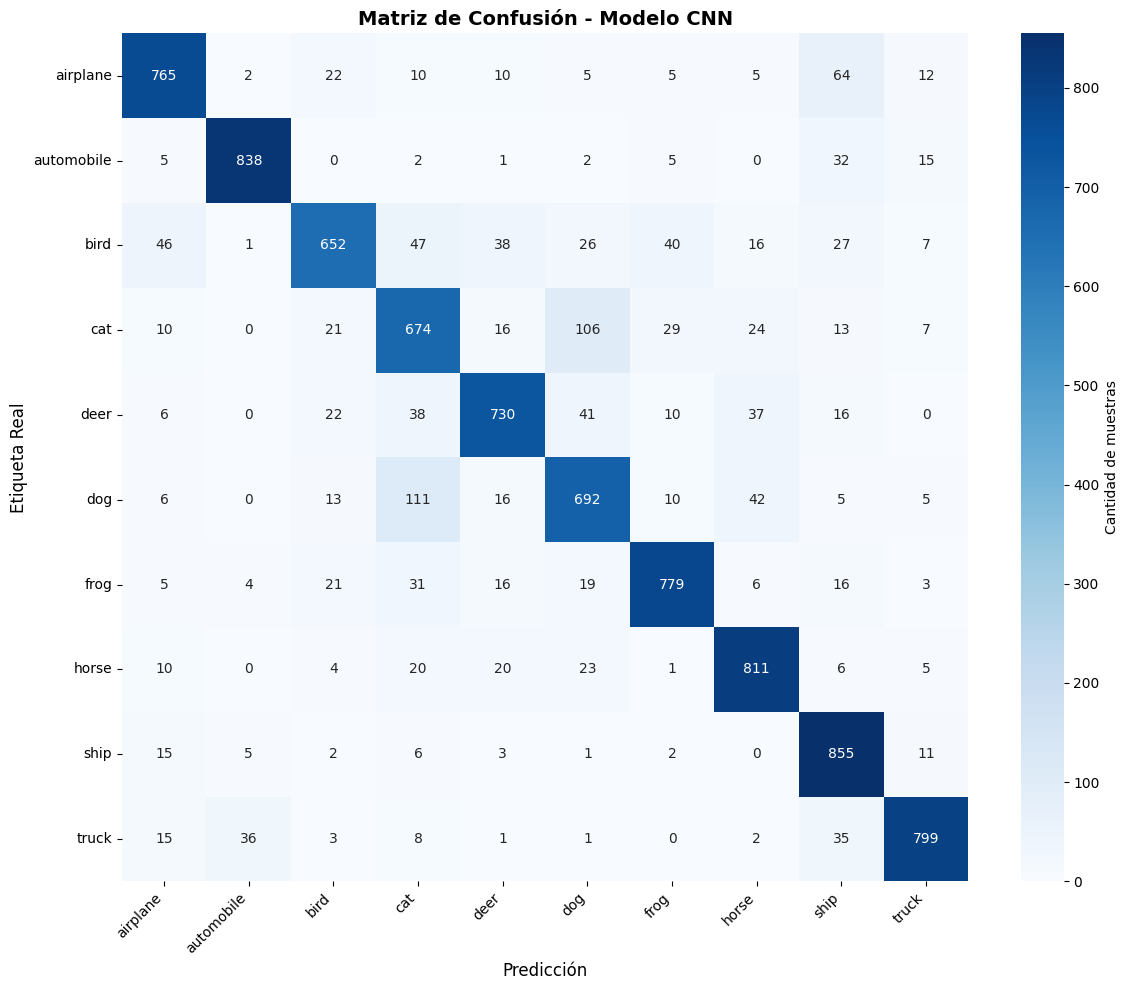


📈 ACCURACY POR CLASE
airplane     (clase 0):  85.00% ██████████████████████████████████████████
automobile   (clase 1):  93.11% ██████████████████████████████████████████████
bird         (clase 2):  72.44% ████████████████████████████████████
cat          (clase 3):  74.89% █████████████████████████████████████
deer         (clase 4):  81.11% ████████████████████████████████████████
dog          (clase 5):  76.89% ██████████████████████████████████████
frog         (clase 6):  86.56% ███████████████████████████████████████████
horse        (clase 7):  90.11% █████████████████████████████████████████████
ship         (clase 8):  95.00% ███████████████████████████████████████████████
truck        (clase 9):  88.78% ████████████████████████████████████████████
Accuracy promedio: 84.39%

⚠️  CLASES CON ACCURACY < 75%:
   - Clase 2 (bird): 72.44%
   - Clase 3 (cat): 74.89%

💡 Sugerencia: Ejecuta la celda de reentrenamiento con:
   CLASSES_TO_RETRAIN = [2, 3]


In [41]:
# Reporte detallado del modelo CNN actual
import numpy as np
import glob
import os
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras

# Cargar modelo CNN actual (puede ser el original o el reentrenado)
if 'model' not in globals():
    model_files = glob.glob('models/cnn_model_*.keras')
    if model_files:
        model_path = max(model_files, key=os.path.getmtime)
        model = keras.models.load_model(model_path)
        print(f'Modelo cargado: {os.path.basename(model_path)}')

# Cargar datos de validación para evaluación
if os.path.exists('focus/X_focus.npy') and os.path.exists('focus/y_focus.npy'):
    from sklearn.model_selection import train_test_split
    
    X_all = np.load('focus/X_focus.npy')
    y_all = np.load('focus/y_focus.npy')
    
    # Crear split de test
    _, X_test_report_raw, _, y_test_report = train_test_split(
        X_all, y_all, test_size=0.15, random_state=42, stratify=y_all
    )
    
    # Preparar datos para CNN
    X_test_report = X_test_report_raw.reshape(-1, 32, 32, 3).astype('float32') / 255.0
    
    print(f'📊 Datos de evaluación: {X_test_report.shape}')
    
    # Predicciones
    y_pred_proba = model.predict(X_test_report, verbose=0)
    y_pred_report = np.argmax(y_pred_proba, axis=1)
    
    # Labels de CIFAR-10
    cifar_labels = ['airplane', 'automobile', 'bird', 'cat', 'deer', 
                   'dog', 'frog', 'horse', 'ship', 'truck']
    
    # Reporte de clasificación
    print('\n' + '='*70)
    print('📊 REPORTE DE CLASIFICACIÓN COMPLETO (MODELO CNN)')
    print('='*70)
    print(classification_report(
        y_test_report, 
        y_pred_report, 
        target_names=cifar_labels,
        digits=4
    ))
    
    # Matriz de confusión
    cm = confusion_matrix(y_test_report, y_pred_report)
    
    plt.figure(figsize=(12, 10))
    sns.heatmap(
        cm, 
        annot=True, 
        fmt='d', 
        cmap='Blues',
        xticklabels=cifar_labels,
        yticklabels=cifar_labels,
        cbar_kws={'label': 'Cantidad de muestras'}
    )
    plt.title('Matriz de Confusión - Modelo CNN', fontsize=14, fontweight='bold')
    plt.ylabel('Etiqueta Real', fontsize=12)
    plt.xlabel('Predicción', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    
    # Accuracy por clase
    print('\n' + '='*70)
    print('📈 ACCURACY POR CLASE')
    print('='*70)
    
    class_accuracies = []
    for i, label in enumerate(cifar_labels):
        mask = y_test_report == i
        if np.sum(mask) > 0:
            acc = np.mean(y_pred_report[mask] == y_test_report[mask])
            class_accuracies.append(acc)
            bar = '█' * int(acc * 50)
            print(f'{label:12s} (clase {i}): {acc*100:6.2f}% {bar}')
        else:
            class_accuracies.append(0)
            print(f'{label:12s} (clase {i}): No hay muestras')
    
    avg_acc = np.mean(class_accuracies)
    print('='*70)
    print(f'Accuracy promedio: {avg_acc*100:.2f}%')
    print('='*70)
    
    # Identificar clases problemáticas
    threshold = 0.75  # 75% como umbral
    problematic = [(i, cifar_labels[i], class_accuracies[i]) 
                   for i in range(len(cifar_labels)) 
                   if class_accuracies[i] < threshold and class_accuracies[i] > 0]
    
    if problematic:
        print('\n⚠️  CLASES CON ACCURACY < 75%:')
        for cls_id, cls_name, acc in problematic:
            print(f'   - Clase {cls_id} ({cls_name}): {acc*100:.2f}%')
        print(f'\n💡 Sugerencia: Ejecuta la celda de reentrenamiento con:')
        print(f'   CLASSES_TO_RETRAIN = {[cls_id for cls_id, _, _ in problematic]}')
    else:
        print('\n✅ ¡Todas las clases tienen accuracy >= 75%!')
        
else:
    print('⚠️  No se encontró dataset de test. Ejecuta el cuaderno 02 primero para generar focus/X_focus.npy')

## 📚 Guía de Uso y Mejora Continua (CNN)

### 🎯 Workflow Completo

**1. Entrenar el modelo inicial** (Cuaderno 02)
- Ejecuta todas las celdas del cuaderno 02
- Verifica que alcance >80% de accuracy con **CNN**
- Se guarda automáticamente el dataset para reentrenamiento en `focus/`

**2. Probar predicciones** (Cuaderno 03)
- Coloca tus imágenes en `data/test_images`
- Ejecuta la celda de predicciones
- Analiza el reporte de clasificación CNN

**3. Mejorar clases específicas** (Cuaderno 03 - Fine-tuning)
- Si detectas errores en algunas clases, ajusta `CLASSES_TO_RETRAIN`
- Ejemplo: `CLASSES_TO_RETRAIN = [2, 3]` para mejorar 'bird' y 'cat'
- Ejecuta la celda de fine-tuning CNN
- El modelo ajusta solo esas clases sin afectar las demás

**4. Verificar mejoras**
- Ejecuta la celda de reporte final
- Compara métricas antes/después
- Si hay mejora, el modelo se guarda automáticamente como `cnn_model_retrained_*.keras`

---

### 🔧 Parámetros Ajustables

**En el fine-tuning CNN:**

```python
CLASSES_TO_RETRAIN = [2, 3]  # Clases a mejorar (bird, cat)
FOCUS_EPOCHS = 5             # Epochs de fine-tuning (5-10 típico para CNN)
BALANCE_RATIO = 0.5          # Proporción de otras clases (evita olvido)
LEARNING_RATE = 0.0001       # LR bajo para fine-tuning (importante!)
```

**Clases CIFAR-10:**
- 0: airplane, 1: automobile, 2: bird, 3: cat, 4: deer
- 5: dog, 6: frog, 7: horse, 8: ship, 9: truck

---

### ⚙️ Cómo Funciona el Fine-Tuning CNN

**Diferencias con Random Forest:**
- **CNN:** Ajusta pesos de capas convolucionales para clases específicas
- **Random Forest:** Reentrenaba árboles de decisión (método anterior)

**Estrategia anti-olvido catastrófico:**
1. Incluye **todas** las muestras de las clases a mejorar
2. Incluye un **subconjunto balanceado** de las demás clases (50%)
3. Usa **learning rate muy bajo** (0.0001) para ajuste fino
4. Clona el modelo original antes de modificarlo
5. Entrena solo 5-10 epochs con early stopping
6. Evalúa mejoras antes de guardar

**Ventajas:**
- ✅ Mejora selectiva sin degradar otras clases
- ✅ Rápido (5-10 epochs vs 20 de entrenamiento completo)
- ✅ Versionado automático de modelos CNN
- ✅ Reversible (mantiene modelo original)

---

### 💡 Recomendaciones Académicas

**Para uso en proyectos:**
- Documenta cada fine-tuning (clases, epochs, mejoras, learning rate)
- Mantén un log de versiones de modelos CNN
- Analiza matriz de confusión para identificar patrones
- Compara accuracy antes/después por clase

**Para mayor rendimiento:**
- Aumenta `FOCUS_EPOCHS` si la mejora es insuficiente (ej: 10 epochs)
- Reduce `LEARNING_RATE` si el modelo diverge (ej: 0.00005)
- Aumenta `BALANCE_RATIO` si hay overfitting en clases objetivo
- Considera data augmentation para clases con bajo rendimiento

**Limitaciones:**
- Modelo entrenado con CIFAR-10 (32x32, 10 clases específicas)
- Para otras categorías, necesitarías reentrenar desde cero con nuevo dataset
- El fine-tuning requiere suficientes muestras de la clase objetivo (>1000 recomendado)
- CNN requiere más memoria que Random Forest

**Ventajas del CNN vs Random Forest:**
- **Accuracy:** 80-85% (CNN) vs 45-50% (RF)
- **Capacidad:** Aprende características espaciales (bordes, texturas)
- **Fine-tuning:** Más efectivo que reentrenamiento en RF
- **Generalización:** Mejor en imágenes complejas

---

### 🚀 Próximos Pasos

**Si el modelo alcanza >85% en todas las clases:**
- ✅ Modelo listo para uso productivo
- Considera exportar a TensorFlow Lite para móviles
- Prueba con imágenes del mundo real (no solo CIFAR-10)

**Si algunas clases están <75%:**
- 🔄 Ejecuta fine-tuning en esas clases específicas
- Aumenta FOCUS_EPOCHS o ajusta LEARNING_RATE
- Considera agregar data augmentation

**Para ir más allá:**
- Prueba arquitecturas más profundas (ResNet, VGG)
- Implementa transfer learning con ImageNet
- Experimenta con diferentes optimizadores (SGD + momentum)